# Metaheuristics and other solution methods for the CVRPTW: a visual guide

**Goal.** Compare every candidate method for our routing problem (CVRPTW with peak traffic), so that the team can choose together. Each method has: the idea in one paragraph, a figure, its advantages and its disadvantages.

**How to read the figures.** All figures are *schematic*. They are computed by small toy programs (a 1-D landscape, a few random customers) written for this notebook. They illustrate how each method behaves. **They are not benchmarks** of the methods on our problem. Real comparisons will come from our own experiments.

**Vocabulary used throughout**

| Term | Meaning |
|---|---|
| Solution | One complete plan: which customers each truck serves, and in which order |
| Cost | The value to minimise (here the total distance) |
| Neighbour | A solution obtained from another by one small change (move a customer, swap two, ...) |
| Global optimum | The best solution among all |
| Local optimum | Better than all its neighbours, but not the best overall |
| Intensification | Searching thoroughly around the current good area |
| Diversification | Exploring areas that are very different from the current one |

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.lines import Line2D

plt.rcParams.update({"figure.dpi": 100, "axes.spines.top": False,
                     "axes.spines.right": False, "font.size": 10})

# ---------- 1-D toy landscape: the x axis stands for "all possible solutions" ----------
X = np.linspace(-3.5, 3.5, 141)
def f(x): return 0.05*(x**2 - 4)**2 + 0.15*x + 0.10*np.sin(3*x)
F = f(X)
GLOB = int(np.argmin(F))
LM = [i for i in range(1, len(X)-1) if F[i] < F[i-1] and F[i] < F[i+1]]

def hill_climb(i):
    path = [i]
    while True:
        nb = [j for j in (i-1, i+1) if 0 <= j < len(X)]
        b = min(nb, key=lambda j: F[j])
        if F[b] < F[i]:
            i = b; path.append(i)
        else:
            return path

def tabu_search(i, iters=90, tenure=6):
    tabu, best, path, bests = {}, i, [i], [F[i]]
    for it in range(iters):
        nb = [j for j in (i-1, i+1) if 0 <= j < len(X)
              and (tabu.get(j, -1) < it or F[j] < F[best])]      # aspiration criterion
        if not nb: break
        j = min(nb, key=lambda k: F[k])                           # best non-tabu neighbour
        tabu[i] = it + tenure                                     # forbid coming back
        i = j; path.append(i)
        if F[i] < F[best]: best = i
        bests.append(F[best])
    return path, best, bests

def landscape(ax):
    ax.plot(X, F, color="0.6", lw=2)
    ax.scatter(X[LM], F[LM], c="tab:red", s=28, zorder=3)
    ax.scatter(X[GLOB], F[GLOB], c="tab:green", marker="*", s=200, zorder=4)
    ax.set_xlabel("solutions (toy 1-D space)"); ax.set_ylabel("cost"); ax.set_xticks([])

# ---------- toy customers for the routing figures ----------
rng = np.random.default_rng(7)
DEPOT = np.array([5.0, 5.0])
def dist(a, b): return float(np.linalg.norm(a - b))
def route_len(P, r):
    path = [DEPOT] + [P[k] for k in r] + [DEPOT]
    return sum(dist(path[a], path[a+1]) for a in range(len(path)-1))
def total(P, routes): return sum(route_len(P, r) for r in routes)
def nn_routes(P, cap=5):
    left, routes = set(range(len(P))), []
    while left:
        r, cur = [], DEPOT
        while left and len(r) < cap:
            j = min(left, key=lambda k: dist(P[k], cur)); r.append(j); left.remove(j); cur = P[j]
        routes.append(r)
    return routes
COL = ["tab:blue", "tab:orange", "tab:green", "tab:purple", "tab:brown"]
def draw_routes(ax, P, routes, title="", removed=(), number=False):
    for c, r in enumerate(routes):
        path = np.array([DEPOT] + [P[k] for k in r] + [DEPOT])
        ax.plot(path[:, 0], path[:, 1], "-o", color=COL[c % 5], ms=5, lw=1.6)
        if number:
            for rank, k in enumerate(r, 1):
                ax.annotate(str(rank), P[k], xytext=(4, 4), textcoords="offset points", fontsize=8)
    for k in removed:
        ax.scatter(*P[k], marker="x", c="red", s=70, zorder=5)
    ax.scatter(*DEPOT, marker="s", c="black", s=70, zorder=6)
    ax.set_title(title, fontsize=10); ax.set_aspect("equal"); ax.set_xticks([]); ax.set_yticks([])
print("toy landscape: %d local optima, global optimum at index %d" % (len(LM), GLOB))

toy landscape: 2 local optima, global optimum at index 25


# Summary table

| # | Method | Family | Idea in one line | Advantages | Disadvantages | Role for us |
|---|---|---|---|---|---|---|
| 1 | Construction heuristics (Solomon I1, savings) | Constructive | Build a plan once, customer by customer | Very fast, feasible start, easy | One solution only, mediocre quality, never corrected | Initial solutions |
| 2 | Hill Climbing | Local search | Always move to the best better neighbour | Simple, fast (Workshop 4.1) | Stops at the first local optimum, deterministic | Baseline |
| 3 | Multi-Start Hill Climbing | Local search + restarts | Repeat Hill Climbing from random starts | One more loop, fewer bad stops | Restarts learn nothing, wasteful | Baseline |
| 4 | Tabu Search | Trajectory | Best non-tabu neighbour, even if worse | Escapes local optima, same code skeleton, proven on VRPTW | Tabu size to tune, full neighbourhood is costly | **Main candidate** |
| 5 | Tabu Multi-Start | Trajectory + restarts | Several complete Tabu runs, keep the best | Intensification + diversification | Cost multiplied by the number of runs | **Main candidate** |
| 6 | Granular Tabu Search | Trajectory | Only moves between close, time-compatible customers | Makes thousands of customers feasible | One more parameter (κ), may hide a good move | **Recommended add-on** |
| 7 | Simulated Annealing | Trajectory | Accept worse moves with a probability that shrinks | Very simple, same neighbourhood | Cooling schedule is hard to tune, no memory | Alternative to compare |
| 8 | GRASP | Constructive + local search | Randomised greedy start, then local search | Good and varied starts | No memory between iterations | Better start generator |
| 9 | Iterated Local Search (ILS) | Trajectory | Descend, shake the solution, descend again | Simple, restarts from a good solution | Strength of the shake must be tuned | Possible variant |
| 10 | Variable Neighbourhood Search (VNS) | Trajectory | Change the type of move when stuck | Uses our operators directly, few parameters | Order of neighbourhoods to design | Possible extension |
| 11 | LNS / ALNS | Destroy and repair | Remove part of the plan, rebuild it better | Very effective on large routing instances | Heavier to implement | **Plan B** |
| 12 | Genetic algorithm (HGS-like) | Population | Cross two solutions, mutate, select | Among the best on VRP | Crossover breaks time windows, heavy in memory, long to code | Too ambitious at first |
| 13 | Ant Colony Optimisation | Population | Ants build routes guided by pheromone | Learns promising arcs | Slow, n×n memory, hard to tune | Not retained |
| 14 | Particle Swarm Optimisation | Population | Particles move with a velocity towards good positions | Great for continuous variables | A route is a sequence, not a point: awkward encoding | Not retained |
| 15 | Exact methods (ILP, branch-and-price) | Exact | Prove optimality with a solver | Optimal, gives the reference cost C* | Time explodes with n | Small instances only |

The sections below explain each method with a figure.

# 0. Building blocks: the neighbourhood moves

Most methods below (2 to 11) need a **neighbourhood**: the set of small changes that turn a solution into another. For a routing problem the classical moves are *relocate* (move one customer), *swap* (exchange two customers), *2-opt* (reverse a part of one route) and *2-opt\** (exchange the ends of two routes). The figure shows the last two, since they are the least obvious.

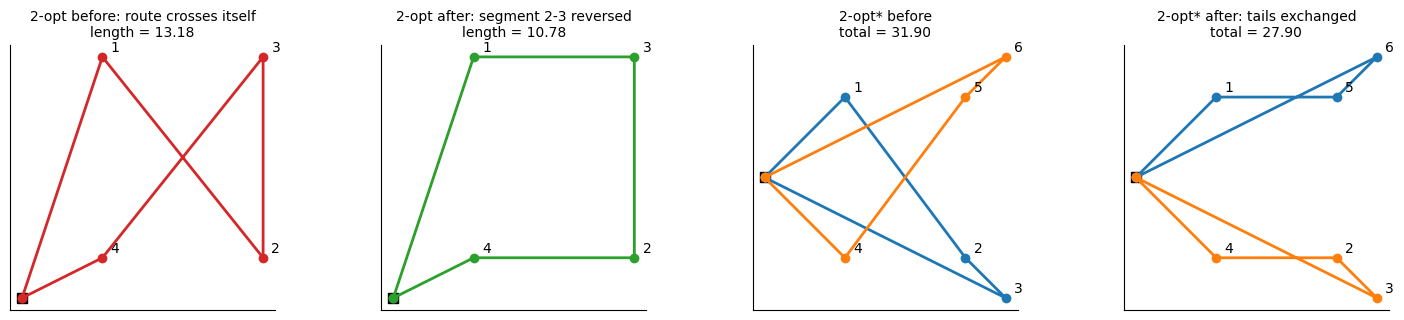

In [2]:
# 2-opt: untangle a route that crosses itself (single route)
D = np.array([0.0, 0.0])
pts = {1: (1, 3), 2: (3, 0.5), 3: (3, 3), 4: (1, 0.5)}
def L(seq, p=pts):
    path = [D] + [np.array(p[k]) for k in seq] + [D]
    return sum(dist(path[a], path[a+1]) for a in range(len(path)-1))
def plot_seq(ax, seq, title, p=pts, color="tab:blue"):
    path = np.array([D] + [p[k] for k in seq] + [D])
    ax.plot(path[:, 0], path[:, 1], "-o", color=color, lw=2)
    for k in seq: ax.annotate(str(k), p[k], xytext=(6, 4), textcoords="offset points")
    ax.scatter(*D, marker="s", c="k", s=60); ax.set_title(title, fontsize=10)
    ax.set_aspect("equal"); ax.set_xticks([]); ax.set_yticks([])
fig, ax = plt.subplots(1, 4, figsize=(15, 3.3))
b, a = [1, 2, 3, 4], [1, 3, 2, 4]
plot_seq(ax[0], b, "2-opt before: route crosses itself\nlength = %.2f" % L(b), color="tab:red")
plot_seq(ax[1], a, "2-opt after: segment 2-3 reversed\nlength = %.2f" % L(a), color="tab:green")

# 2-opt*: exchange the tails of two routes
P2 = {1: (2, 2), 2: (5, -2), 3: (6, -3), 4: (2, -2), 5: (5, 2), 6: (6, 3)}
def plot_two(ax, r1, r2, title):
    for r, c in ((r1, "tab:blue"), (r2, "tab:orange")):
        path = np.array([D] + [P2[k] for k in r] + [D])
        ax.plot(path[:, 0], path[:, 1], "-o", color=c, lw=2)
        for k in r: ax.annotate(str(k), P2[k], xytext=(6, 4), textcoords="offset points")
    ax.scatter(*D, marker="s", c="k", s=60); ax.set_title(title, fontsize=10)
    ax.set_aspect("equal"); ax.set_xticks([]); ax.set_yticks([])
bb = ([1, 2, 3], [4, 5, 6]); aa = ([1, 5, 6], [4, 2, 3])
plot_two(ax[2], *bb, "2-opt* before\ntotal = %.2f" % (L(bb[0], P2) + L(bb[1], P2)))
plot_two(ax[3], *aa, "2-opt* after: tails exchanged\ntotal = %.2f" % (L(aa[0], P2) + L(aa[1], P2)))
plt.tight_layout(); plt.show()

**Why it matters with time windows.** 2-opt* keeps the direction of each tail, so the visiting order inside each tail does not change. Plain 2-opt reverses a segment, which changes the arrival time at every customer of that segment, so all their windows must be re-checked.

# 1. Construction heuristics (Solomon I1, savings)

**Idea.** Build a plan in one pass, without ever going back. Open a route, then repeatedly add the customer that costs the least detour while capacity and time windows allow it. When nobody fits, open a new truck.

**Figure.** A simplified version (nearest customer first, at most 5 customers per truck, no time windows) building routes on random customers. The numbers are the order of visit.

**Advantages**
* Very fast.
* The solution is feasible from the start.
* Easy to implement.

**Disadvantages**
* A single solution, usually of mediocre quality.
* Never corrected afterwards.

**Role for us.** Generate initial solutions for the metaheuristics.

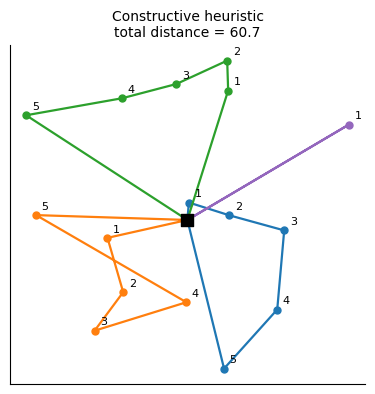

In [3]:
P = rng.uniform(0, 10, (16, 2))
R0 = nn_routes(P, cap=5)
fig, ax = plt.subplots(figsize=(4.6, 4.4))
draw_routes(ax, P, R0, "Constructive heuristic\ntotal distance = %.1f" % total(P, R0), number=True)
plt.show()

# 2. Hill Climbing

**Idea.** Start from a solution, look at all neighbours, move to the best one if it is better, repeat. Stop when no neighbour is better. Like a hiker who only walks downhill and stops at the first dip.

**Figure.** The toy landscape. Red dots are local optima, the green star is the global optimum. Starting from the same point, Hill Climbing stops in the nearest dip.

**Advantages**
* Simple and fast (Workshop 4.1).
* A good baseline to measure what the other methods bring.

**Disadvantages**
* Stops at the first local optimum: intensification without any diversification.
* Deterministic: the same start always gives the same result.

**Role for us.** Baseline.

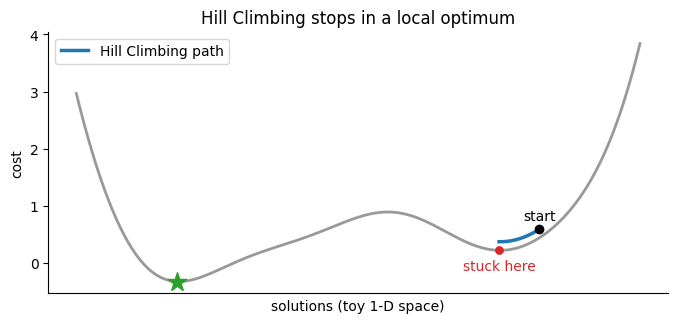

In [4]:
# choose a start where Hill Climbing fails but a longer Tabu Search succeeds (for a clear illustration)
START = next((s for s in range(len(X)-1, 0, -1)
              if hill_climb(s)[-1] != GLOB and tabu_search(s)[1] == GLOB), len(X)-5)
hc = hill_climb(START)
fig, ax = plt.subplots(figsize=(8, 3.4))
landscape(ax)
ax.plot(X[hc], F[hc] + 0.15, color="tab:blue", lw=2.5, label="Hill Climbing path")
ax.scatter(X[START], F[START] + 0.15, c="k", zorder=5); ax.annotate("start", (X[START], F[START] + 0.3), ha="center")
ax.annotate("stuck here", (X[hc[-1]], F[hc[-1]] - 0.35), ha="center", color="tab:red")
ax.legend(loc="upper left"); ax.set_title("Hill Climbing stops in a local optimum")
plt.show()

# 3. Hill Climbing Multi-Start

**Idea.** Run Hill Climbing from several random starting points and keep the best result.

**Figure.** Eight random starts. Each ends in a dip. Only some reach the global optimum; keeping the best of them is the whole strategy.

**Advantages**
* One extra loop around Hill Climbing.
* The risk of ending in a bad dip decreases.

**Disadvantages**
* Each restart starts from scratch and learns nothing from the others.
* Wasteful: many restarts end in the same dips.
* On large instances only a few restarts fit in the time budget.

**Role for us.** Baseline.

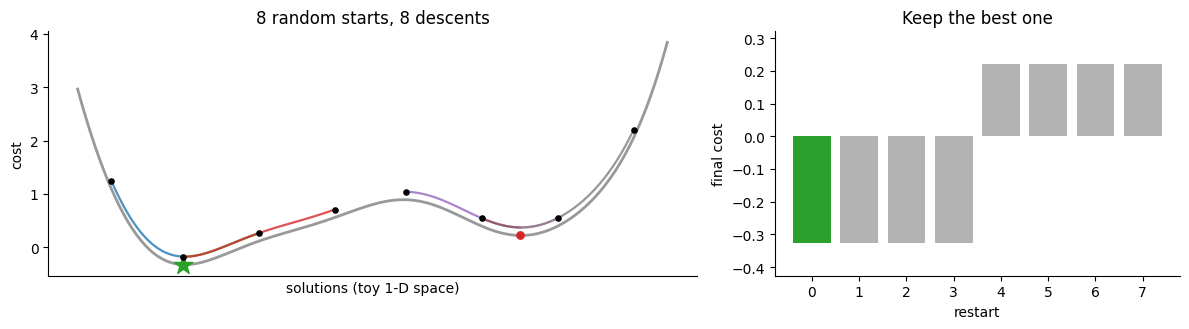

In [5]:
starts = np.linspace(8, 132, 8).astype(int)
res = [hill_climb(s) for s in starts]
fig, ax = plt.subplots(1, 2, figsize=(12, 3.4), gridspec_kw={"width_ratios": [1.6, 1]})
landscape(ax[0])
for s, p in zip(starts, res):
    ax[0].plot(X[p], F[p] + 0.15, lw=1.6, alpha=.8)
    ax[0].scatter(X[s], F[s] + 0.15, c="k", s=14, zorder=5)
ax[0].set_title("8 random starts, 8 descents")
final = np.array([F[p[-1]] for p in res]); best = final.argmin()
ax[1].bar(range(8), final, color=["tab:green" if i == best else "0.7" for i in range(8)])
ax[1].set_xlabel("restart"); ax[1].set_ylabel("final cost"); ax[1].set_title("Keep the best one")
ax[1].set_ylim(final.min() - 0.1, final.max() + 0.1)
plt.tight_layout(); plt.show()

# 4. Tabu Search

**Idea.** Hill Climbing with two changes. (1) Move to the best neighbour that is **not tabu**, even if it is worse than the current solution. (2) Remember the last moves in a **tabu list**, so that the search does not walk straight back. A move that beats the best known solution is allowed even if tabu (*aspiration criterion*).

**Figure.** Same start as before. Hill Climbing (blue) stops. Tabu Search (orange) climbs out of the dip because going back is forbidden, and finds the global optimum. The right panel shows the current cost (it goes up sometimes) and the best cost found so far.

**Advantages**
* Same code skeleton as Hill Climbing (Workshop 4.1): neighbourhood, best neighbour, plus a `deque`.
* Escapes local optima.
* A reference method for routing with time windows.

**Disadvantages**
* The tabu size must be tuned: too small, it cycles; too large, it blocks the search (Workshop 4.2).
* Exploring the full neighbourhood is expensive when n is large.

**Role for us.** Main candidate.

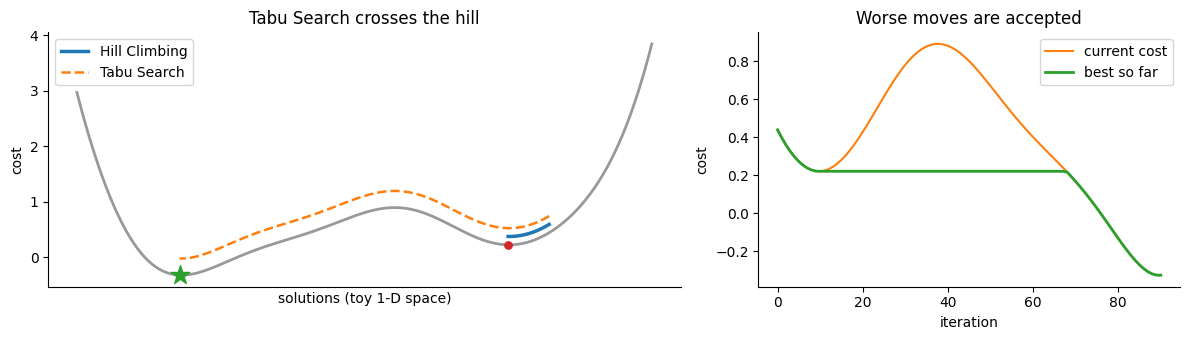

In [6]:
path, best, bests = tabu_search(START)
fig, ax = plt.subplots(1, 2, figsize=(12, 3.5), gridspec_kw={"width_ratios": [1.5, 1]})
landscape(ax[0])
ax[0].plot(X[hc], F[hc] + 0.15, color="tab:blue", lw=2.5, label="Hill Climbing")
ax[0].plot(X[path], F[path] + 0.3, color="tab:orange", lw=1.8, ls="--", label="Tabu Search")
ax[0].legend(loc="upper left"); ax[0].set_title("Tabu Search crosses the hill")
ax[1].plot([F[i] for i in path], color="tab:orange", label="current cost")
ax[1].plot(bests, color="tab:green", lw=2, label="best so far")
ax[1].set_xlabel("iteration"); ax[1].set_ylabel("cost"); ax[1].legend(); ax[1].set_title("Worse moves are accepted")
plt.tight_layout(); plt.show()

# 5. Tabu Multi-Start

**Idea.** Run several complete Tabu Searches from different starting points and keep the best solution. Tabu Search digs well around one point; the restarts visit different regions.

**Figure.** Five Tabu runs one after another (grey bands alternate). The green curve is the best cost found so far over the whole experiment. It can only improve when a new run finds something better.

**Advantages**
* Local intensification and global diversification combined (Workshop 4.1).
* Less sensitive to the starting solution.

**Disadvantages**
* Computing cost multiplied by the number of runs.
* The time budget must be split between the length of a run and the number of runs.

**Role for us.** Main candidate.

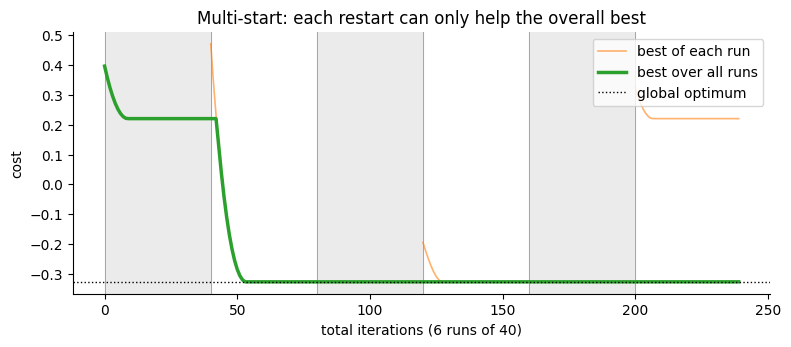

In [7]:
r2 = np.random.default_rng(3)
runs, iters = 6, 40
starts = r2.integers(0, len(X), runs)
overall, offset, cur_best = [], 0, np.inf
fig, ax = plt.subplots(figsize=(9, 3.4))
for k, s in enumerate(starts):
    _, _, b = tabu_search(int(s), iters=iters)
    b = b[:iters]; b = b + [b[-1]] * (iters - len(b))
    ax.plot(range(offset, offset + len(b)), b, color="tab:orange", alpha=.6, lw=1.2,
            label="best of each run" if k == 0 else None)
    for v in b:
        cur_best = min(cur_best, v); overall.append(cur_best)
    if k % 2 == 0: ax.axvspan(offset, offset + iters, color="0.92", zorder=0)
    ax.axvline(offset, color="0.6", lw=0.6)
    offset += iters
ax.plot(overall, color="tab:green", lw=2.5, label="best over all runs")
ax.axhline(F[GLOB], color="k", ls=":", lw=1, label="global optimum")
ax.set_xlabel("total iterations (6 runs of 40)"); ax.set_ylabel("cost"); ax.legend(loc="upper right")
ax.set_title("Multi-start: each restart can only help the overall best")
plt.show()

# 6. Granular Tabu Search

**Idea.** With thousands of customers, looking at every possible move (about n² of them) is too slow. Keep only moves that connect a customer with its κ nearest neighbours that are also compatible in time. Most of the other moves are poor anyway.

**Figure.** Left: all candidate arcs from one customer. Right: only its κ = 5 nearest. The same idea is applied to every customer.

**Advantages**
* One iteration becomes much cheaper, so thousands of customers become feasible.
* Little quality is lost: good moves are almost always between nearby customers.

**Disadvantages**
* One more parameter, κ, to tune.
* A κ that is too small can hide a useful move.

**Role for us.** Recommended add-on to Tabu Search (Toth and Vigo).

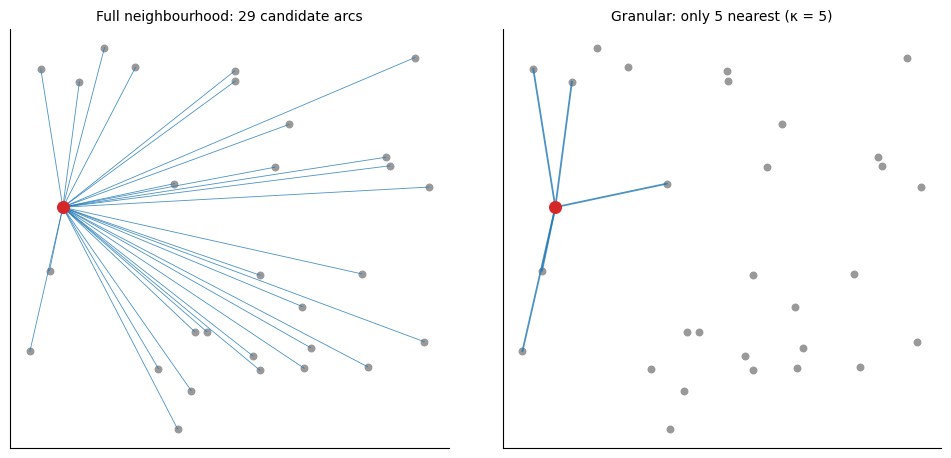

In [8]:
Q = rng.uniform(0, 10, (30, 2)); i0 = 7; kappa = 5
d = np.array([dist(Q[i0], q) for q in Q]); order = [j for j in np.argsort(d) if j != i0]
fig, ax = plt.subplots(1, 2, figsize=(10, 4.6))
for a, targets, ttl in ((ax[0], order, "Full neighbourhood: %d candidate arcs" % len(order)),
                        (ax[1], order[:kappa], "Granular: only %d nearest (κ = %d)" % (kappa, kappa))):
    a.scatter(Q[:, 0], Q[:, 1], c="0.6", s=22)
    for j in targets:
        a.plot([Q[i0, 0], Q[j, 0]], [Q[i0, 1], Q[j, 1]], color="tab:blue", lw=1.3 if len(targets) < 10 else 0.6, alpha=.8)
    a.scatter(*Q[i0], c="tab:red", s=70, zorder=5); a.set_title(ttl, fontsize=10)
    a.set_aspect("equal"); a.set_xticks([]); a.set_yticks([])
plt.tight_layout(); plt.show()

# 7. Simulated Annealing

**Idea.** Pick one random neighbour. If it is better, take it. If it is worse, take it with probability exp(−Δ/T), where Δ is how much worse and T the "temperature". T decreases over time, like a cooling metal: at first almost everything is accepted, at the end almost nothing.

**Figure.** Left: acceptance probability of a worse move for different temperatures. Right: a run on the toy landscape. The cost jumps around at the beginning and settles at the end.

**Advantages**
* Very simple to code, same neighbourhood as Tabu Search.
* Escapes local optima.

**Disadvantages**
* The starting temperature and the cooling rate are delicate and depend on the instance size.
* No memory: can come back to the same solutions.

**Role for us.** Alternative to compare with Tabu Search.

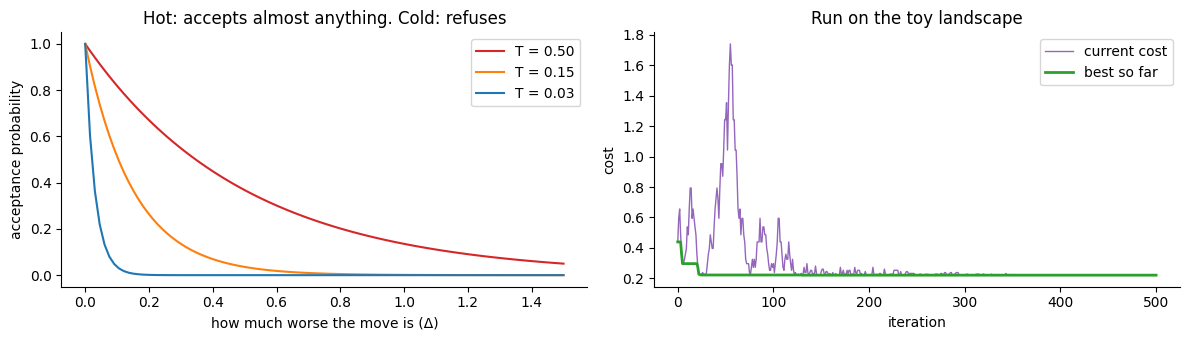

In [9]:
def simulated_annealing(i, iters=500, T0=0.6, alpha=0.985, seed=0):
    r = np.random.default_rng(seed); T, cur, best = T0, i, i
    costs, temps = [F[i]], [T0]
    for _ in range(iters):
        j = int(np.clip(cur + r.choice([-3, -2, -1, 1, 2, 3]), 0, len(X) - 1))
        dlt = F[j] - F[cur]
        if dlt < 0 or r.random() < np.exp(-dlt / T): cur = j
        if F[cur] < F[best]: best = cur
        T *= alpha; costs.append(F[cur]); temps.append(T)
    return np.array(costs), np.array(temps)
fig, ax = plt.subplots(1, 2, figsize=(12, 3.5))
dl = np.linspace(0, 1.5, 100)
for T, c in ((0.5, "tab:red"), (0.15, "tab:orange"), (0.03, "tab:blue")):
    ax[0].plot(dl, np.exp(-dl / T), color=c, label="T = %.2f" % T)
ax[0].set_xlabel("how much worse the move is (Δ)"); ax[0].set_ylabel("acceptance probability"); ax[0].legend()
ax[0].set_title("Hot: accepts almost anything. Cold: refuses")
costs, temps = simulated_annealing(START)
ax[1].plot(costs, color="tab:purple", lw=1, label="current cost")
ax[1].plot(np.minimum.accumulate(costs), color="tab:green", lw=2, label="best so far")
ax[1].set_xlabel("iteration"); ax[1].set_ylabel("cost"); ax[1].legend(); ax[1].set_title("Run on the toy landscape")
plt.tight_layout(); plt.show()

# 8. GRASP

**Idea.** Repeat two steps: (1) a *randomised* greedy construction: at each step, build a short list of the best candidates and pick one **at random** from that list (not always the best); (2) a local search from the result. It is a Multi-Start whose starting points are smarter than pure random ones.

**Figure.** Candidate customers ranked by insertion cost. Greedy always picks the first bar. GRASP picks randomly among the bars under the threshold (the restricted candidate list).

**Advantages**
* Starts are both good and varied.
* Easy to combine with Tabu Search.

**Disadvantages**
* No memory between iterations: each start is independent.
* The size of the candidate list (α) must be tuned.

**Role for us.** A better generator of initial solutions.

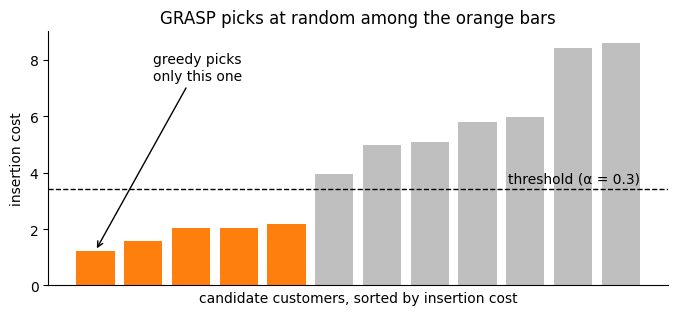

In [10]:
r3 = np.random.default_rng(11)
cost = np.sort(r3.uniform(1, 9, 12))
alpha = 0.3; thr = cost.min() + alpha * (cost.max() - cost.min())
fig, ax = plt.subplots(figsize=(8, 3.3))
ax.bar(range(12), cost, color=["tab:orange" if c <= thr else "0.75" for c in cost])
ax.axhline(thr, color="k", ls="--", lw=1)
ax.text(11.4, thr + 0.2, "threshold (α = 0.3)", ha="right")
ax.annotate("greedy picks\nonly this one", (0, cost[0]), xytext=(1.2, 7.3), arrowprops=dict(arrowstyle="->"))
ax.set_xlabel("candidate customers, sorted by insertion cost"); ax.set_ylabel("insertion cost")
ax.set_title("GRASP picks at random among the orange bars"); ax.set_xticks([])
plt.show()

# 9. Iterated Local Search (ILS)

**Idea.** Descend to a local optimum, then **shake** the solution (for example move a few customers at random), then descend again. You restart from the current good solution, not from scratch.

**Figure.** Each cycle is: kick (red, the cost jumps up), descent (blue). The line shows the cost of the local optimum after each descent.

**Advantages**
* Simple, often efficient.
* Sits between Hill Climbing and Multi-Start: keeps the good part of the solution.

**Disadvantages**
* The strength of the shake must be tuned: too weak and you fall back in the same dip; too strong and it is a random restart.

**Role for us.** Possible variant.

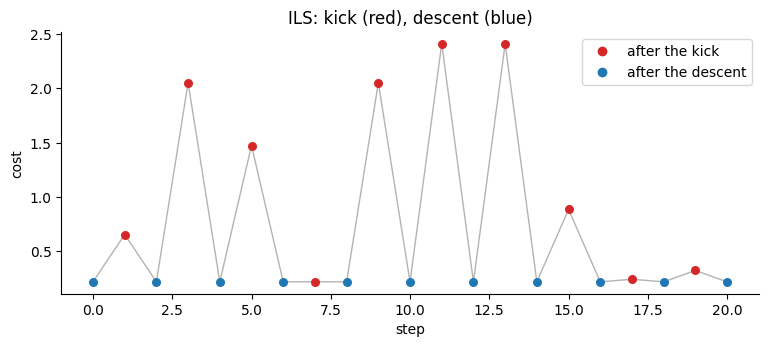

In [11]:
def ils(i, rounds=10, kick=30, seed=4):
    r = np.random.default_rng(seed)
    cur = hill_climb(i)[-1]; hist = [("local", F[cur])]; accepted = [F[cur]]
    for _ in range(rounds):
        k = int(np.clip(cur + r.integers(-kick, kick + 1), 0, len(X) - 1))
        hist.append(("kick", F[k]))
        new = hill_climb(k)[-1]; hist.append(("local", F[new]))
        if F[new] <= F[cur]: cur = new
        accepted.append(F[cur])
    return hist, accepted
hist, accepted = ils(START)
fig, ax = plt.subplots(figsize=(9, 3.4))
ax.plot([h[1] for h in hist], color="0.7", lw=1)
for n, (t, v) in enumerate(hist):
    ax.scatter(n, v, c="tab:red" if t == "kick" else "tab:blue", s=30, zorder=3)
ax.set_xlabel("step"); ax.set_ylabel("cost"); ax.set_title("ILS: kick (red), descent (blue)")
ax.legend(handles=[Line2D([], [], marker="o", ls="", color="tab:red", label="after the kick"),
                   Line2D([], [], marker="o", ls="", color="tab:blue", label="after the descent")], loc="upper right")
plt.show()

# 10. Variable Neighbourhood Search (VNS)

**Idea.** Use several types of neighbourhood, from small to large (relocate, swap, 2-opt*, ...). When the current one gives no improvement, switch to a larger one. A dip for one type of move is often not a dip for another.

**Figure.** Around a solution that is a local optimum for the smallest neighbourhood N1, a better solution exists, but only the larger neighbourhood N2 can reach it.

**Advantages**
* Uses our routing operators directly.
* Few parameters.

**Disadvantages**
* The order and the definition of the neighbourhoods must be designed.
* More logic to write than a simple Tabu Search.

**Role for us.** Possible extension.

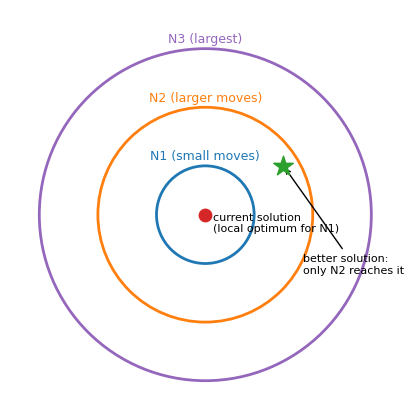

In [12]:
fig, ax = plt.subplots(figsize=(5.2, 5.2))
for r, c, n in ((1.0, "tab:blue", "N1 (small moves)"), (2.2, "tab:orange", "N2 (larger moves)"), (3.4, "tab:purple", "N3 (largest)")):
    ax.add_patch(plt.Circle((0, 0), r, fill=False, color=c, lw=2))
    ax.text(0, r + 0.12, n, ha="center", color=c, fontsize=9)
ax.scatter(0, 0, c="tab:red", s=80, zorder=4); ax.text(0.15, -0.35, "current solution\n(local optimum for N1)", fontsize=8)
ax.scatter(1.6, 1.0, c="tab:green", marker="*", s=220, zorder=4)
ax.annotate("better solution:\nonly N2 reaches it", (1.6, 1.0), xytext=(2.0, -1.2), fontsize=8, arrowprops=dict(arrowstyle="->"))
ax.set_xlim(-4, 4); ax.set_ylim(-4, 4.2); ax.set_aspect("equal"); ax.axis("off")
plt.show()

# 11. LNS / ALNS (Large Neighbourhood Search)

**Idea.** Instead of tiny moves, **destroy** a part of the solution (remove 5 to 20 % of the customers) and **repair** it by reinserting them as well as possible. ALNS (Adaptive LNS) chooses by itself which destroy and repair operators work best. It is like taking out a piece of a puzzle and refitting it better.

**Figure.** Left: the starting plan. Middle: the customers with the longest detours are removed (red crosses). Right: they are reinserted at their cheapest position.

**Advantages**
* Very effective on large routing instances.
* Changes a large part of the solution in one step.

**Disadvantages**
* Heavier to implement (destroy operators, repair operators, adaptive weights).

**Role for us.** Plan B if the target gap is not reached.

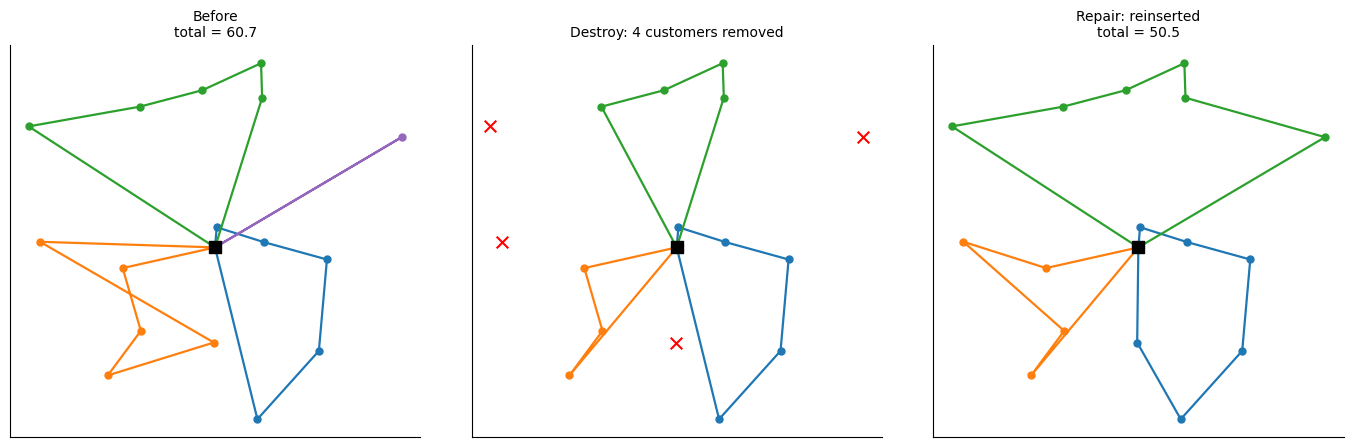

In [13]:
def remove_gain(P, routes, k):
    for r in routes:
        if k in r:
            r2 = [x for x in r if x != k]
            return route_len(P, r) - route_len(P, r2)
def lns_step(P, routes, n_remove=4, cap=6):
    allc = [k for r in routes for k in r]
    removed = sorted(allc, key=lambda k: -remove_gain(P, routes, k))[:n_remove]   # worst removal
    work = [[k for k in r if k not in removed] for r in routes]
    for k in removed:                                                            # cheapest insertion
        best = (np.inf, None, None)
        for ri, r in enumerate(work):
            if len(r) >= cap: continue
            for pos in range(len(r) + 1):
                c = route_len(P, r[:pos] + [k] + r[pos:]) - route_len(P, r)
                if c < best[0]: best = (c, ri, pos)
        _, ri, pos = best; work[ri].insert(pos, k)
    return removed, [r for r in work if r]
removed, R1 = lns_step(P, R0)
R_mid = [[k for k in r if k not in removed] for r in R0]
fig, ax = plt.subplots(1, 3, figsize=(14, 4.4))
draw_routes(ax[0], P, R0, "Before\ntotal = %.1f" % total(P, R0))
draw_routes(ax[1], P, R_mid, "Destroy: %d customers removed" % len(removed), removed=removed)
draw_routes(ax[2], P, R1, "Repair: reinserted\ntotal = %.1f" % total(P, R1))
plt.tight_layout(); plt.show()

# 12. Genetic algorithm (HGS-like)

**Idea.** Keep a **population** of solutions. At each generation, **cross** two parents to make a child, **mutate** it a little, and keep the best individuals. The crossover mixes good parts of two plans.

**Figure.** A simplified order crossover on a list of 8 customers: a block of parent 1 (orange) is copied, and the missing customers are filled in the order of parent 2.

**Advantages**
* Among the best methods on the VRP (the HGS of Vidal et al.).
* Explores globally.

**Disadvantages**
* The crossover easily breaks the time windows.
* Stores many solutions: heavy in memory with thousands of customers.
* Longest to implement.

**Role for us.** Too ambitious as a first choice.

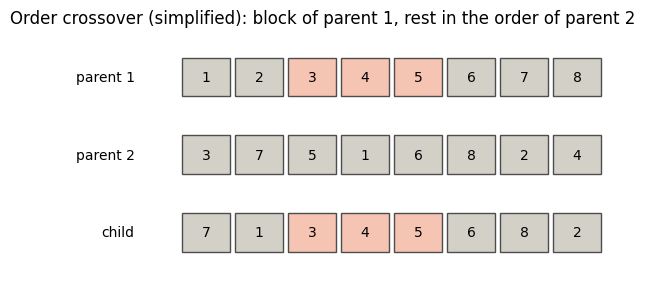

In [14]:
p1 = [1, 2, 3, 4, 5, 6, 7, 8]; p2 = [3, 7, 5, 1, 6, 8, 2, 4]; a, b = 2, 5
child = [None] * 8; child[a:b] = p1[a:b]
fill = iter([g for g in p2 if g not in child])
child = [g if g is not None else next(fill) for g in child]
fig, ax = plt.subplots(figsize=(8, 3.2))
def draw_row(y, seq, label, hi=None):
    ax.text(-0.9, y, label, ha="right", va="center")
    for k, g in enumerate(seq):
        c = "#F5C4B3" if (hi and hi[0] <= k < hi[1]) else "#D3D1C7"
        ax.add_patch(plt.Rectangle((k, y - 0.3), 0.9, 0.6, color=c, ec="0.3"))
        ax.text(k + 0.45, y, str(g), ha="center", va="center")
draw_row(2.4, p1, "parent 1", (a, b)); draw_row(1.2, p2, "parent 2"); draw_row(0, child, "child", (a, b))
ax.set_xlim(-3.2, 8.5); ax.set_ylim(-0.7, 3.1); ax.axis("off")
ax.set_title("Order crossover (simplified): block of parent 1, rest in the order of parent 2")
plt.show()

# 13. Ant Colony Optimisation (ACO)

**Idea.** Virtual ants build routes step by step. The more an arc was used in good solutions, the more **pheromone** it carries and the more it attracts the next ants. The pheromone evaporates over time, so bad choices are forgotten.

**Figure.** Arc thickness is the amount of pheromone. After some iterations, the arcs of the good route are strongly marked.

**Advantages**
* Natural for building routes.
* Learns which arcs are promising.

**Disadvantages**
* Slow and memory-hungry (an n × n pheromone matrix: far too big for thousands of customers).
* Hard to tune (evaporation, influence of pheromone vs distance).

**Role for us.** Not retained.

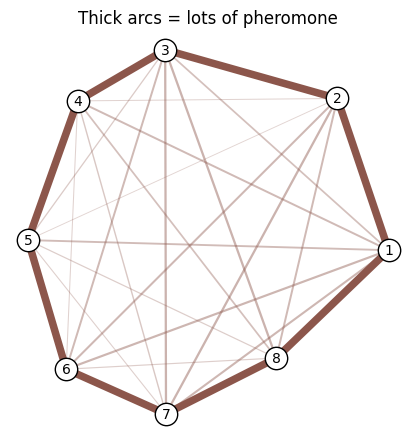

In [15]:
n = 8; ang = np.linspace(0, 2*np.pi, n, endpoint=False) + np.random.default_rng(2).uniform(-.15, .15, n)
rad = np.random.default_rng(5).uniform(2.2, 3.2, n); N = np.c_[rad*np.cos(ang), rad*np.sin(ang)]
tau = np.random.default_rng(9).uniform(0.05, 0.25, (n, n))
for k in range(n): tau[k, (k+1) % n] = tau[(k+1) % n, k] = 1.0
fig, ax = plt.subplots(figsize=(5.4, 5.2))
for i in range(n):
    for j in range(i+1, n):
        ax.plot(N[[i, j], 0], N[[i, j], 1], color="tab:brown", lw=0.4 + 5*tau[i, j], alpha=min(1, 0.2 + tau[i, j]))
ax.scatter(N[:, 0], N[:, 1], c="white", ec="k", s=260, zorder=3)
for i in range(n): ax.text(N[i, 0], N[i, 1], str(i+1), ha="center", va="center", zorder=4)
ax.set_title("Thick arcs = lots of pheromone"); ax.set_aspect("equal"); ax.axis("off")
plt.show()

# 14. Particle Swarm Optimisation (PSO)

**Idea.** Particles move in a continuous space. Each one has a position and a velocity, and is attracted both by the best position it has seen and by the best position of the whole swarm.

**Figure.** Contours of a 2-D function. Each arrow is the next move of a particle, pulled towards the best particle (star). This works well because a position is just a pair of numbers.

**Advantages**
* Very good for continuous variables.
* Few parameters.

**Disadvantages**
* A route is an **ordered list of customers**, not a point of a continuous space. It needs an artificial encoding (for example sorting real numbers into a permutation), which is awkward and rarely competitive for routing.

**Role for us.** Not retained.

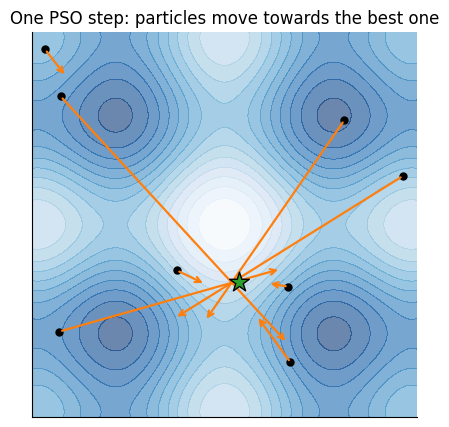

In [16]:
def f2(x, y): return 0.05*(x**2 + y**2) + 0.6*(2 - np.cos(1.5*x) - np.cos(1.5*y))
gx, gy = np.meshgrid(np.linspace(-4, 4, 200), np.linspace(-4, 4, 200))
r4 = np.random.default_rng(6); pos = r4.uniform(-3.8, 3.8, (9, 2)); vel = r4.uniform(-.5, .5, (9, 2))
val = f2(pos[:, 0], pos[:, 1]); g = pos[val.argmin()]
new_v = 0.5*vel + 1.5*r4.random((9, 1))*(g - pos)
fig, ax = plt.subplots(figsize=(5.6, 5))
ax.contourf(gx, gy, f2(gx, gy), levels=18, cmap="Blues", alpha=.6)
ax.scatter(pos[:, 0], pos[:, 1], c="k", s=25, zorder=3)
for p, v in zip(pos, new_v): ax.annotate("", p + v, p, arrowprops=dict(arrowstyle="->", color="tab:orange", lw=1.6))
ax.scatter(*g, marker="*", c="tab:green", s=220, zorder=4, ec="k")
ax.set_title("One PSO step: particles move towards the best one"); ax.set_aspect("equal"); ax.set_xticks([]); ax.set_yticks([])
plt.show()

# 15. Exact methods (ILP, branch-and-price)

**Idea.** Write the problem as an integer linear program (our Section 2) and let a solver **prove** optimality.

**Figure.** The shape of the typical behaviour: the solving time of an exact method grows exponentially with the number of customers, while a heuristic grows slowly. **The numbers are invented to show the shape of the curves. They are not measurements.**

**Advantages**
* The optimal solution is guaranteed.
* Gives the optimal cost C\* that serves as a reference to compute the gap of our heuristic.

**Disadvantages**
* The running time explodes with n (the problem is NP-hard).
* Only practical for a few tens to about a hundred customers, far from several thousand.

**Role for us.** Small instances only, to measure the quality of the heuristic.

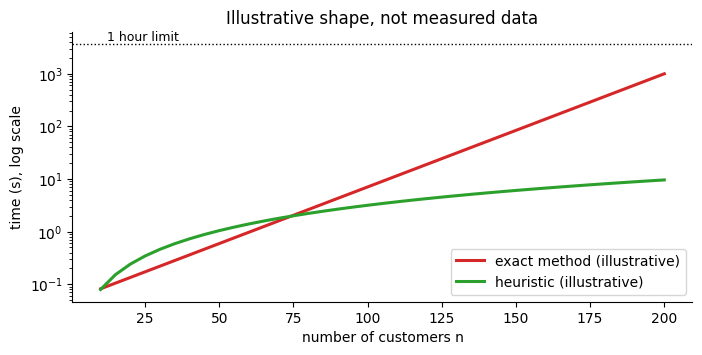

In [17]:
n = np.arange(10, 201, 5)
exact = 0.05 * 2**(n/14); heur = 0.002 * n**1.6
fig, ax = plt.subplots(figsize=(8, 3.5))
ax.semilogy(n, exact, color="tab:red", lw=2.2, label="exact method (illustrative)")
ax.semilogy(n, heur, color="tab:green", lw=2.2, label="heuristic (illustrative)")
ax.axhline(3600, color="k", ls=":", lw=1); ax.text(12, 4200, "1 hour limit", fontsize=9)
ax.set_xlabel("number of customers n"); ax.set_ylabel("time (s), log scale"); ax.legend(loc="lower right")
ax.set_title("Illustrative shape, not measured data")
plt.show()

# Comparing all methods at a glance

The heatmap below is **our qualitative judgement** (0 = none, 5 = very strong), based on the descriptions above and the literature. It is a discussion support, not a measurement.

* *Intensification*: how well the method refines a good area.
* *Diversification*: how well it explores different areas.
* *Scalability*: how well it handles several thousand customers.
* *Ease*: how easy it is to implement (5 = easy).

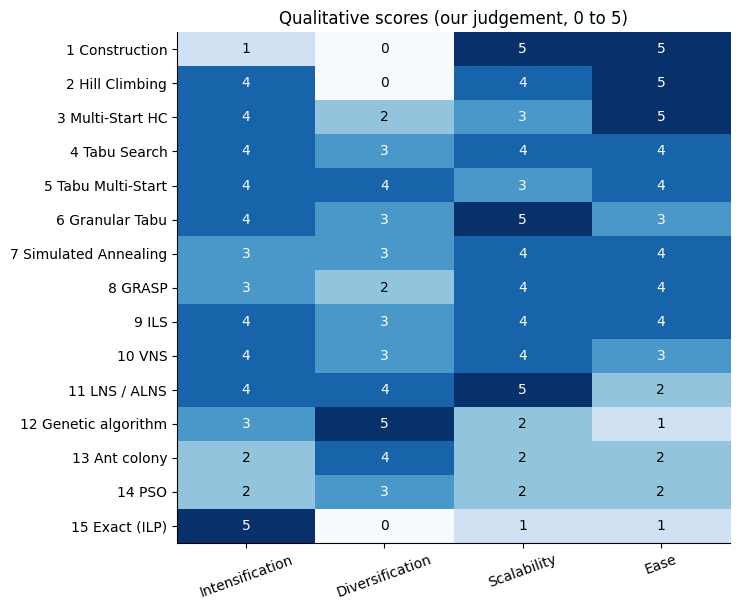

In [18]:
M = {  # intensification, diversification, scalability, ease of implementation
 "1 Construction":      (1, 0, 5, 5),
 "2 Hill Climbing":     (4, 0, 4, 5),
 "3 Multi-Start HC":    (4, 2, 3, 5),
 "4 Tabu Search":       (4, 3, 4, 4),
 "5 Tabu Multi-Start":  (4, 4, 3, 4),
 "6 Granular Tabu":     (4, 3, 5, 3),
 "7 Simulated Annealing": (3, 3, 4, 4),
 "8 GRASP":             (3, 2, 4, 4),
 "9 ILS":               (4, 3, 4, 4),
 "10 VNS":              (4, 3, 4, 3),
 "11 LNS / ALNS":       (4, 4, 5, 2),
 "12 Genetic algorithm": (3, 5, 2, 1),
 "13 Ant colony":       (2, 4, 2, 2),
 "14 PSO":              (2, 3, 2, 2),
 "15 Exact (ILP)":      (5, 0, 1, 1),
}
names = list(M); data = np.array([M[k] for k in names])
fig, ax = plt.subplots(figsize=(7.5, 6.2))
im = ax.imshow(data, cmap="Blues", vmin=0, vmax=5, aspect="auto")
ax.set_xticks(range(4)); ax.set_xticklabels(["Intensification", "Diversification", "Scalability", "Ease"], rotation=20)
ax.set_yticks(range(len(names))); ax.set_yticklabels(names)
for i in range(len(names)):
    for j in range(4):
        ax.text(j, i, data[i, j], ha="center", va="center", color="white" if data[i, j] >= 3 else "black")
ax.set_title("Qualitative scores (our judgement, 0 to 5)")
plt.tight_layout(); plt.show()

# Suggested choice and questions for the team

**Proposal.**
* **Main method:** Granular Tabu Search with Multi-Start, started from randomised insertion solutions.
* **Baselines for the comparison (No Free Lunch):** Hill Climbing, Multi-Start Hill Climbing, plain Tabu Search.
* **Plan B** if the 7 to 10 % gap target is not reached on the largest instances: ALNS.
* **Reference quality:** the exact ILP on small instances.

**Questions to settle together**
1. One carefully studied method, or two very different ones to compare (for example Tabu Search and Simulated Annealing)?
2. How much implementation time do we have? A genetic algorithm or an ALNS costs much more than Tabu Search.
3. Who codes what? The neighbourhood moves and the time-window feasibility check are the delicate part.
4. Objective: distance or experienced travel time? Fleet size: hard bound or minimised? (open decisions in `NOTATION.md`)